# DEV · Problema 1 · CardioRitmo: tamizaje de latidos
**Responsable:** Diana · Specs del cliente en la prueba (umbral 0.5): sensibilidad ≥ 95 %, especificidad ≥ 95 %, modelo con ≤ 20,000 parámetros.

Regla: todo se decide con validación; la prueba se usa UNA sola vez, en la sección 6.

In [1]:
import os, random
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, confusion_matrix
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)
MAX_PARAMS = 20_000

## 1. Datos y exploración

In [2]:
ecg = pd.read_csv("https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv", header=None)
X = ecg.iloc[:, :-1].to_numpy("float32")   # 140 puntos por latido
y = 1 - ecg.iloc[:, -1].to_numpy("int64")  # el archivo trae 1 = normal; aquí 1 = ANORMAL

# Prueba del cliente: 20 % estratificado. No la toquen hasta el final.
X_resto, X_prueba, y_resto, y_prueba = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Latidos totales:", X.shape[0], "| puntos por latido:", X.shape[1])
print("X_resto:", X_resto.shape, "| X_prueba:", X_prueba.shape)
print("Rango de valores: min %.2f, max %.2f, media %.3f, desv %.3f" % (X.min(), X.max(), X.mean(), X.std()))
print("Valores faltantes:", int(np.isnan(X).sum()))
for nombre, yy in [("total", y), ("resto", y_resto), ("prueba", y_prueba)]:
    print(f"{nombre:7s} anormales: {yy.sum():4d} ({yy.mean():.1%}) | normales: {(1-yy).sum():4d} ({1-yy.mean():.1%})")

Latidos totales: 4998 | puntos por latido: 140
X_resto: (3998, 140) | X_prueba: (1000, 140)
Rango de valores: min -7.09, max 7.40, media -0.000, desv 0.996
Valores faltantes: 0
total   anormales: 2079 (41.6%) | normales: 2919 (58.4%)
resto   anormales: 1663 (41.6%) | normales: 2335 (58.4%)
prueba  anormales:  416 (41.6%) | normales:  584 (58.4%)


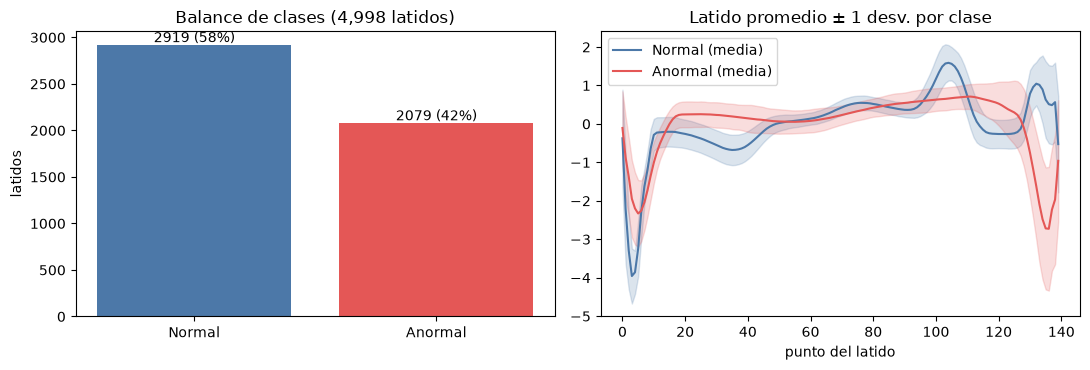

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
conteo = pd.Series(y).map({0: "Normal", 1: "Anormal"}).value_counts()
ax[0].bar(conteo.index, conteo.values, color=["#4C78A8", "#E45756"])
for i, v in enumerate(conteo.values):
    ax[0].text(i, v + 30, f"{v} ({v/len(y):.0%})", ha="center")
ax[0].set_title("Balance de clases (4,998 latidos)"); ax[0].set_ylabel("latidos")

t = np.arange(140)
for cls, color, nom in [(0, "#4C78A8", "Normal"), (1, "#E45756", "Anormal")]:
    m, s = X[y == cls].mean(0), X[y == cls].std(0)
    ax[1].plot(t, m, color=color, label=f"{nom} (media)")
    ax[1].fill_between(t, m - s, m + s, color=color, alpha=0.2)
ax[1].set_title("Latido promedio ± 1 desv. por clase"); ax[1].set_xlabel("punto del latido"); ax[1].legend()
plt.tight_layout(); plt.show()

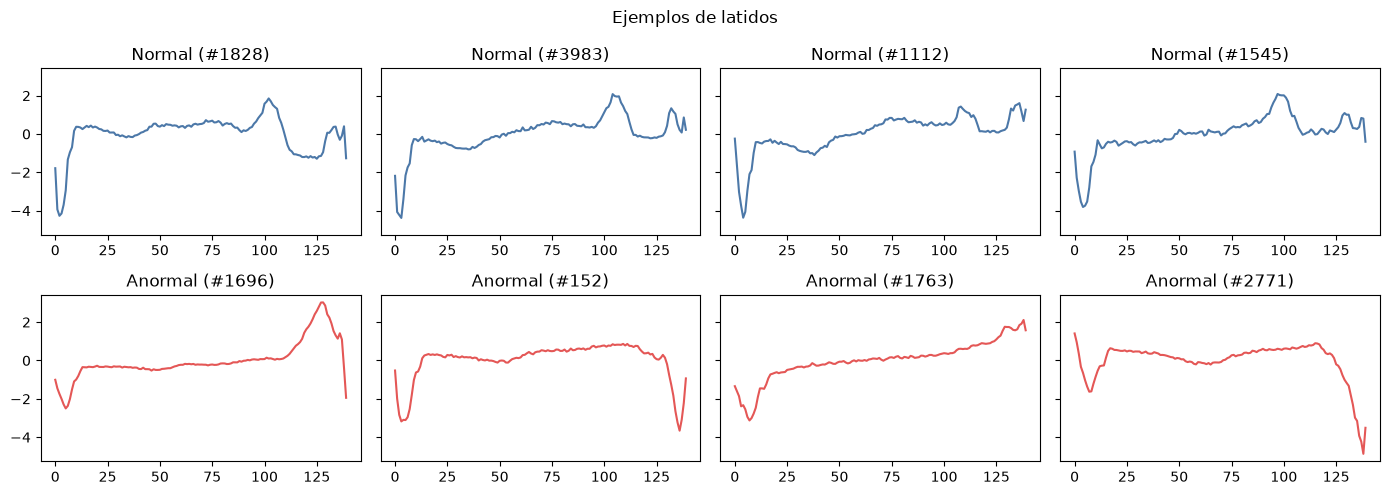

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5), sharey=True)
rng = np.random.RandomState(0)
for r, (cls, nom, color) in enumerate([(0, "Normal", "#4C78A8"), (1, "Anormal", "#E45756")]):
    idx = rng.choice(np.where(y_resto == cls)[0], 4, replace=False)
    for c, i in enumerate(idx):
        axes[r, c].plot(X_resto[i], color=color); axes[r, c].set_title(f"{nom} (#{i})")
plt.suptitle("Ejemplos de latidos"); plt.tight_layout(); plt.show()

**Observaciones:** los latidos ya vienen normalizados (media ≈ 0, desviación ≈ 1; rango de −7.1 a 7.4) y no hay valores faltantes. Hay 58.4 % de latidos normales y 41.6 % anormales: balance razonable, sin remuestreo; la prueba conserva la misma proporción (estratificada). Los latidos normales tienen una forma muy regular (banda estrecha alrededor del promedio) y los anormales se desvían sobre todo en el tramo final (puntos ~100–140). Todos los latidos provienen de **un solo paciente**: esto limita lo que podemos afirmar sobre otros pacientes.

## 2. Preparación (sin fuga)
- Prueba: la indicada por el cliente (no se toca hasta la sección 6).
- Entrenamiento y validación: 80/20 estratificado de `X_resto`.
- Transformación: estandarización global (un solo valor de media y desviación, **calculados solo con entrenamiento**) y forma `(latidos, 140, 1)` para las redes.

In [5]:
X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.2, stratify=y_resto, random_state=SEED)

mu, sigma = X_train.mean(), X_train.std()          # solo con train
prep = lambda A: ((A - mu) / sigma)[..., None].astype("float32")
Xtr, Xva, Xte = prep(X_train), prep(X_val), prep(X_prueba)  # Xte NO se usa hasta la sección 6

print("train", Xtr.shape, "| val", Xva.shape, "| prueba (guardada)", Xte.shape)
print("anormales -> train %.1f%%, val %.1f%%" % (100*y_train.mean(), 100*y_val.mean()))

train (3198, 140, 1) | val (800, 140, 1) | prueba (guardada) (1000, 140, 1)
anormales -> train 41.6%, val 41.6%


## 3. Métricas y línea base trivial
Métricas del cliente con umbral **0.5**: sensibilidad (de cada 100 anormales, cuántos marca) y especificidad (de cada 100 normales, cuántos deja pasar). Se añade AUC.

In [6]:
def metricas(y_true, p, umbral=0.5):
    pred = (np.asarray(p).ravel() >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn); esp = tn / (tn + fp)
    auc = roc_auc_score(y_true, p) if len(set(np.asarray(p).ravel())) > 1 else 0.5
    return {"sensibilidad": sens, "especificidad": esp, "auc": auc}

def cumple(m, params):
    return bool(m["sensibilidad"] >= 0.95 and m["especificidad"] >= 0.95 and params <= MAX_PARAMS)

# Línea base: siempre predice la clase mayoritaria de entrenamiento
mayoritaria = int(y_train.mean() >= 0.5)
p_base_val = np.full(len(y_val), float(mayoritaria))
print("Clase mayoritaria en train:", "ANORMAL" if mayoritaria else "normal")
print("Línea base en validación:", {k: round(v, 3) for k, v in metricas(y_val, p_base_val).items()})

Clase mayoritaria en train: normal
Línea base en validación: {'sensibilidad': np.float64(0.0), 'especificidad': np.float64(1.0), 'auc': 0.5}


## 4. Modelos del parcial (todos ≤ 20,000 parámetros)
Tres arquitecturas vistas en la práctica 3: **Conv1D**, **TCN causal** (convoluciones dilatadas) y **GRU bidireccional**. Se entrenan con `binary_crossentropy`, Adam y `EarlyStopping` sobre la pérdida de validación.

In [7]:
def construir_conv1d():
    return keras.Sequential([
        layers.Input((140, 1)),
        layers.Conv1D(16, 7, padding="same", activation="relu"), layers.MaxPooling1D(2),
        layers.Conv1D(32, 5, padding="same", activation="relu"), layers.MaxPooling1D(2),
        layers.Conv1D(32, 3, padding="same", activation="relu"),
        layers.GlobalAveragePooling1D(), layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid")], name="conv1d")

def construir_tcn():
    inp = layers.Input((140, 1)); x = inp
    for d in [1, 2, 4, 8, 16, 32, 64]:                    # campo receptivo = 255 > 140
        x = layers.Conv1D(16, 3, padding="causal", dilation_rate=d, activation="relu")(x)
    x = layers.Lambda(lambda t: t[:, -1, :])(x)           # último paso: ya vio todo el latido
    x = layers.Dropout(0.3)(x)
    return keras.Model(inp, layers.Dense(1, activation="sigmoid")(x), name="tcn")

def construir_bigru():
    return keras.Sequential([
        layers.Input((140, 1)),
        layers.Bidirectional(layers.GRU(16)), layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid")], name="bigru")

def entrenar(modelo, epocas=80):
    keras.utils.set_random_seed(SEED)
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
                   metrics=[keras.metrics.AUC(name="auc")])
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)]
    h = modelo.fit(Xtr, y_train, validation_data=(Xva, y_val), epochs=epocas, batch_size=64, callbacks=cb, verbose=0)
    return h

modelos, historias = {}, {}
for nombre, f in [("Conv1D", construir_conv1d), ("TCN causal", construir_tcn), ("BiGRU(16)", construir_bigru)]:
    m = f(); h = entrenar(m)
    modelos[nombre], historias[nombre] = m, h
    print(f"{nombre:11s} parámetros: {m.count_params():6d} | épocas: {len(h.history['loss']):2d} | mejor val_loss: {min(h.history['val_loss']):.4f}")

Conv1D      parámetros:   5857 | épocas: 38 | mejor val_loss: 0.0517


TCN causal  parámetros:   4785 | épocas: 20 | mejor val_loss: 0.0543


BiGRU(16)   parámetros:   1857 | épocas: 67 | mejor val_loss: 0.0537


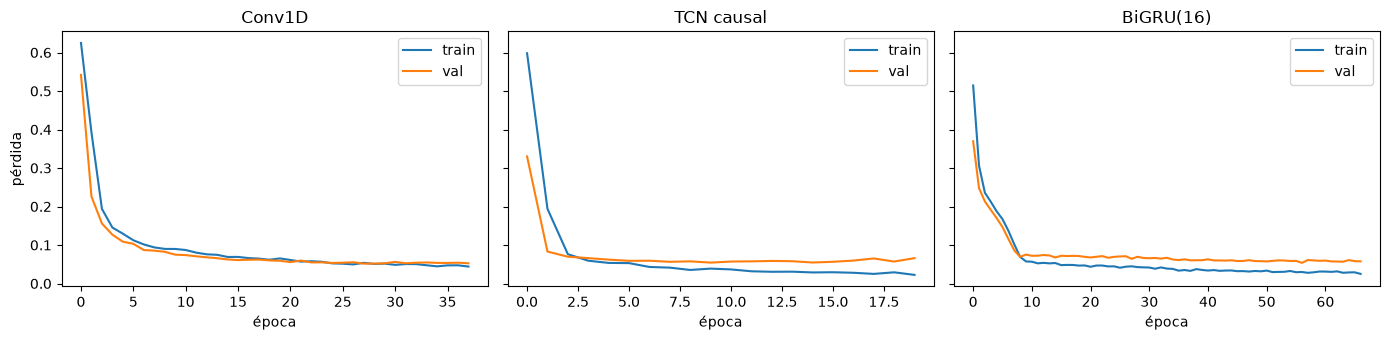

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for a, (nombre, h) in zip(ax, historias.items()):
    a.plot(h.history["loss"], label="train"); a.plot(h.history["val_loss"], label="val")
    a.set_title(nombre); a.set_xlabel("época"); a.legend()
ax[0].set_ylabel("pérdida"); plt.tight_layout(); plt.show()

## 5. Comparación en VALIDACIÓN y elección
La elección se decide aquí, antes de ver la prueba. Regla: entre los modelos que cumplan las specs en validación, el de mayor AUC; si ninguno cumple, el de mayor AUC.

In [9]:
filas = []
bm = metricas(y_val, p_base_val)
filas.append({"modelo": "Línea base (clase mayoritaria)", "parametros": 0, **bm})
for nombre, m in modelos.items():
    mm = metricas(y_val, m.predict(Xva, verbose=0))
    filas.append({"modelo": nombre, "parametros": m.count_params(), **mm})
val_df = pd.DataFrame(filas)
val_df["cumple_val"] = [cumple(r, r["parametros"]) for r in val_df.to_dict("records")]
display(val_df.round(4))

cands = val_df[val_df.modelo.isin(modelos)]
buenos = cands[cands.cumple_val]
elegido_nombre = (buenos if len(buenos) else cands).sort_values("auc", ascending=False).iloc[0]["modelo"]
print("Modelo elegido con validación:", elegido_nombre)

,modelo,parametros,sensibilidad,especificidad,auc,cumple_val
0,Línea base (clase mayoritaria),0,0.000,1.0000,0.5000,False
1,Conv1D,5857,0.961,0.9872,0.9984,True
2,TCN causal,4785,0.985,0.9850,0.9982,True
3,BiGRU(16),1857,0.982,0.9893,0.9972,True


Modelo elegido con validación: Conv1D


## 6. Evaluación única en la PRUEBA y tabla `resultados`
Primera y única vez que se usa la prueba, con umbral 0.5.

In [10]:
tipos = {"Conv1D": "convolucional", "TCN causal": "convolucional", "BiGRU(16)": "recurrente"}
filas = []
mb = metricas(y_prueba, np.full(len(y_prueba), float(mayoritaria)))
filas.append({"modelo": "Línea base (clase mayoritaria)", "tipo": "linea base", "parametros": 0, **mb, "cumple": cumple(mb, 0)})
probs_prueba = {}
for nombre, m in modelos.items():
    p = m.predict(Xte, verbose=0).ravel(); probs_prueba[nombre] = p
    mm = metricas(y_prueba, p)
    filas.append({"modelo": nombre, "tipo": tipos[nombre], "parametros": m.count_params(), **mm, "cumple": cumple(mm, m.count_params())})
resultados = pd.DataFrame(filas)
resultados["elegido"] = resultados["modelo"] == elegido_nombre
resultados.to_csv("resultados_ecg.csv", index=False)
display(resultados.round(4))
print("Elegido:", elegido_nombre, "| elegido=True en", int(resultados.elegido.sum()), "modelo")

,modelo,tipo,parametros,sensibilidad,especificidad,auc,cumple,elegido
0,Línea base (clase mayoritaria),linea base,0,0.0000,1.0000,0.5000,False,False
1,Conv1D,convolucional,5857,0.9856,0.9966,0.9990,True,True
2,TCN causal,convolucional,4785,0.9904,0.9966,0.9987,True,False
3,BiGRU(16),recurrente,1857,0.9808,0.9966,0.9964,True,False


Elegido: Conv1D | elegido=True en 1 modelo


In [11]:
r = resultados[resultados.elegido].iloc[0]
print(f"Con el modelo {r.modelo} (umbral 0.5, prueba de {len(y_prueba)} latidos):")
print(f"  de cada 100 latidos anormales, marca {r.sensibilidad*100:.0f}  (meta: >= 95)")
print(f"  de cada 100 latidos normales, marca como anormales {100-r.especificidad*100:.0f}  (meta: <= 5)")
print(f"  parámetros: {int(r.parametros)} (meta: <= 20,000) | AUC {r.auc:.3f} | cumple: {r.cumple}")

Con el modelo Conv1D (umbral 0.5, prueba de 1000 latidos):
  de cada 100 latidos anormales, marca 99  (meta: >= 95)
  de cada 100 latidos normales, marca como anormales 0  (meta: <= 5)
  parámetros: 5857 (meta: <= 20,000) | AUC 0.999 | cumple: True


## 7. Justificación y análisis de 3 errores

**Por qué se eligió Conv1D.** Los tres modelos del parcial cumplen las specs en validación (sensibilidad y especificidad ≥ 95 %, ≤ 20,000 parámetros) con AUC casi idénticos (0.998 Conv1D, 0.998 TCN, 0.997 BiGRU). Con la regla fijada de antemano (mayor AUC de validación entre los que cumplen) ganó **Conv1D**: 5,857 parámetros (29 % del límite), pesa ~107 KB, es rápida de ejecutar en el monitor y se entrena en segundos. La TCN logró incluso mayor sensibilidad en prueba (99.0 % vs 98.6 %), pero esa diferencia son 2 latidos de 416 y no se usó para decidir (la elección se congeló con validación). La línea base (siempre «normal») tiene 100 % de especificidad pero 0 % de sensibilidad: no sirve para tamizaje.

**Resultado en la prueba (umbral 0.5):** de cada 100 latidos anormales marca ~99 (sensibilidad 98.6 %); de cada 100 normales deja pasar ~99.7 (especificidad 99.7 %). Comete 8 errores en 1,000 latidos: 6 falsos negativos y 2 falsos positivos.

**Error 1 — falso negativo (índice 160, p = 0.02).** Latido anormal con inicio normal (caída profunda ~−4.4 al principio) y un pico R tardío elevado (~1.8 hacia el punto 102), pero el tramo final se parece al de un latido normal. El modelo promedia evidencia sobre todo el latido (GlobalAveragePooling) y la anomalía es localizada y corta, así que queda diluida. Riesgo clínico: un anormal no marcado.

**Error 2 — falso negativo (índice 135, p = 0.03).** Latido anormal con morfología casi normal en la primera mitad y desviación solo en el último tramo (puntos ~125–140). Es el mismo patrón: anomalías pequeñas o al final del latido, donde hay pocas muestras y el modelo apenas pesa esas posiciones. Sugiere que los casos «límite» son los que fallan.

**Error 3 — falso positivo (p = 0.94).** Latido normal con mucho ruido de alta frecuencia que supera ampliamente al latido normal típico. El filtro convolucional interpreta las oscilaciones como forma anormal. En producción esto significa revisión innecesaria, un error menos grave que los falsos negativos, pero muestra sensibilidad al ruido de la señal.

**Limitaciones que se llevan al folleto:** (1) los 4,998 latidos provienen de **un solo paciente** (BIDMC, insuficiencia cardiaca): no hay evidencia de que funcione con otros pacientes, y la prueba es del mismo paciente (no es generalización entre pacientes); (2) los errores son anomalías sutiles y ruido (6 falsos negativos de 416 anormales); (3) con solo 8 errores las diferencias entre modelos no son estadísticamente concluyentes.

Errores del modelo elegido en la prueba: 6 falsos negativos (anormal no marcado), 2 falsos positivos (normal marcado)


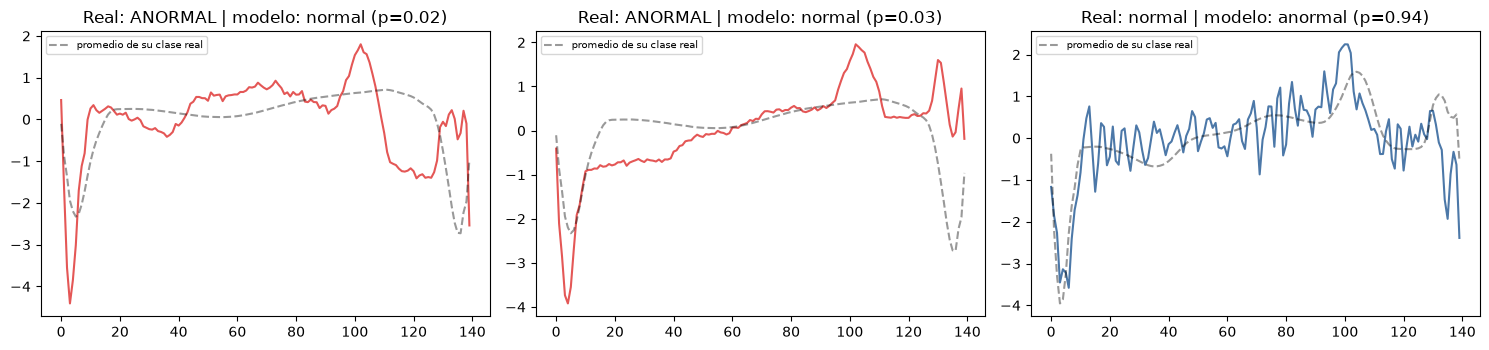

Índices (en X_prueba): [160, 135, 75] | probabilidades: [0.023, 0.028, 0.936]


In [12]:
elegido = modelos[elegido_nombre]
p = probs_prueba[elegido_nombre]; pred = (p >= 0.5).astype(int)
fn = np.where((y_prueba == 1) & (pred == 0))[0]; fp = np.where((y_prueba == 0) & (pred == 1))[0]
print(f"Errores del modelo elegido en la prueba: {len(fn)} falsos negativos (anormal no marcado), {len(fp)} falsos positivos (normal marcado)")
# 3 errores: los más 'seguros' del modelo, priorizando falsos negativos (los más graves clínicamente)
orden_fn = fn[np.argsort(p[fn])] if len(fn) else fn
orden_fp = fp[np.argsort(-p[fp])] if len(fp) else fp
sel = list(orden_fn[:2]) + list(orden_fp[:1])
sel = (sel + list(orden_fn[2:]) + list(orden_fp[1:]))[:3]
fig, axes = plt.subplots(1, len(sel), figsize=(5 * len(sel), 3.6))
axes = np.atleast_1d(axes)
for a, i in zip(axes, sel):
    real = "ANORMAL" if y_prueba[i] else "normal"; dec = "anormal" if pred[i] else "normal"
    a.plot(X_prueba[i], color="#E45756" if y_prueba[i] else "#4C78A8")
    a.plot(X[y == y_prueba[i]].mean(0), "k--", alpha=0.4, label="promedio de su clase real")
    a.set_title(f"Real: {real} | modelo: {dec} (p={p[i]:.2f})"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("Índices (en X_prueba):", [int(i) for i in sel], "| probabilidades:", [round(float(p[i]), 3) for i in sel])

## 8. Guardar el modelo elegido

In [13]:
os.makedirs("modelo", exist_ok=True)
elegido.save("modelo/modelo_ecg.keras")
cargado = keras.models.load_model("modelo/modelo_ecg.keras")
print("Guardado:", os.path.getsize("modelo/modelo_ecg.keras") // 1024, "KB | recarga OK, parámetros:", cargado.count_params())
print("Mismas predicciones tras recargar:", bool(np.allclose(cargado.predict(Xte, verbose=0).ravel(), probs_prueba[elegido_nombre], atol=1e-5)))
# Para usar el modelo en el PMV: estandarizar con estos valores
print("mu =", float(mu), "| sigma =", float(sigma))

Guardado: 107 KB | recarga OK, parámetros: 5857


Mismas predicciones tras recargar: True
mu = 1.704054952700318e-10 | sigma = 0.9964221715927124
